# Les 7 groupes de frieze — art génératif de symétrie 1D

**Navigation** : [Index du rayon](README.md) | [05-0 — générateurs symboliques](05-0-Generateurs-Symboliques.ipynb) | [05-0e — une seule règle de mesure](05-0e-MDL-Mesure-Unique-Python.ipynb)

Une **frieze** (bandeau) est un motif qui se répète le long d'une ligne : une bordure, un liseré, une frise décorative. La question que pose ce carnet est : **combien de façons distinctes un motif peut-il se répéter** tout en conservant des symétries (translation, réflexion, rotation, glissement) ?

La réponse, fondée en cristallographie, est **exactement 7**. Ce sont les **7 groupes de frieze**. Ce carnet les dessine tous, en **art génératif** : à chaque exécution, le motif de base est tiré au hasard, donc **les illustrations ne se répètent jamais** — mais les 7 *types* de symétrie restent bien distingués.

> **Place dans le rayon** : approfondissement de [05-0 — Générateurs symboliques](05-0-Generateurs-Symboliques.ipynb), dont la section 6 présente les groupes de symétrie du plan comme quatrième famille de générateurs (un motif infini engendré par deux générateurs). Ce carnet en prend le cas **1D**, plus petit, où la classification complète tient sur une figure.
>
> **Provenance** : distillation de l'idée de [aberke/coloring-book](https://github.com/aberke/coloring-book) (« A Coloring Book about Group Theory »), **ré-implémentée indépendamment** : la classification des groupes de frieze est un **fait mathématique**, pas l'expression protégée de l'auteur ; le repo est cité comme *inspiration*, ni son code JS ni ses assets ne sont copiés (issue #25324, gate licence, voie a).

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Reproductible par defaut ; le mode "generatif" (seed=None) tire un motif nouveau a chaque exec
SEED = 7
print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__} -- seed {SEED}")

numpy 2.4.2, matplotlib 3.10.8 -- seed 7


## Les 7 groupes, et leurs symétries

Chaque groupe contient toujours la **translation** de période (le motif se répète le long de la ligne). Les 7 groupes se distinguent par les **autres** opérations qu'ils contiennent :

| Groupe | Opérations (outre la translation) | Copies / période | Idée visuelle |
|--------|-----------------------------------|:---:|--------------|
| `p1`   | aucune | 1 | simple répétition à l'identique |
| `p11g` | glissement-réflexion | 2 | un jumeau retourné, décalé d'un demi-période |
| `p1m1` | miroir vertical | 2 | un jumeau en miroir (axe perpendiculaire) |
| `p11m` | miroir horizontal | 2 | un jumeau en miroir (axe parallèle) |
| `p2`   | rotation 180° | 2 | un jumeau à l'envers |
| `p2mg` | miroir + glissement | 4 | la cellule fondamentale double |
| `p2mm` | deux miroirs (→ rotation) | 4 | la cellule fondamentale double |

On va maintenant **construire** chaque bande : on part d'un petit motif de base asymétrique, et on l'applique par toutes les opérations du groupe, puis par translation de période en période.

In [2]:
from fractions import Fraction

from symmetry_art import FRIEZE_OPERATIONS

# Representation canonique : (x, y) -> (sx*x + dx, sy*y), de periode 1.
# Les Fraction evitent qu'un arrondi binaire ne fausse la fermeture.
Operation = tuple[int, int, Fraction]


def normaliser(operation) -> Operation:
    """Ramener la translation horizontale dans [0, 1[."""
    sx, sy, dx = operation
    return int(sx), int(sy), Fraction(str(dx)) % 1


def composer(a, b) -> Operation:
    """Composer a apres b, modulo une translation horizontale entiere."""
    sx, sy, dx = a
    tx, ty, ex = b
    return normaliser((sx * tx, sy * ty, sx * ex + dx))


# Une seule source de verite : la table du module symmetry_art, deja utilisee
# par son moteur de rendu. FRIZE ne fait que normaliser ses coefficients.
FRIZE = {
    groupe: tuple(normaliser(op) for op in operations)
    for groupe, operations in FRIEZE_OPERATIONS.items()
}
N_COPIES = {groupe: len(operations) for groupe, operations in FRIZE.items()}
print("Table importee depuis symmetry_art.FRIEZE_OPERATIONS")
print("copies par periode :", N_COPIES)


def make_motif(seed, n=6):
    """n points colores dans la cellule fondamentale, asymetriques par construction."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(0.15, 0.85, n)
    y = rng.uniform(-0.5, 0.5, n)
    c = rng.uniform(0.1, 0.9, (n, 3))
    return np.column_stack([x, y]), c


Table importee depuis symmetry_art.FRIEZE_OPERATIONS
copies par periode : {'p1': 1, 'p11g': 2, 'p1m1': 2, 'p11m': 2, 'p2': 2, 'p2mg': 4, 'p2mm': 4}


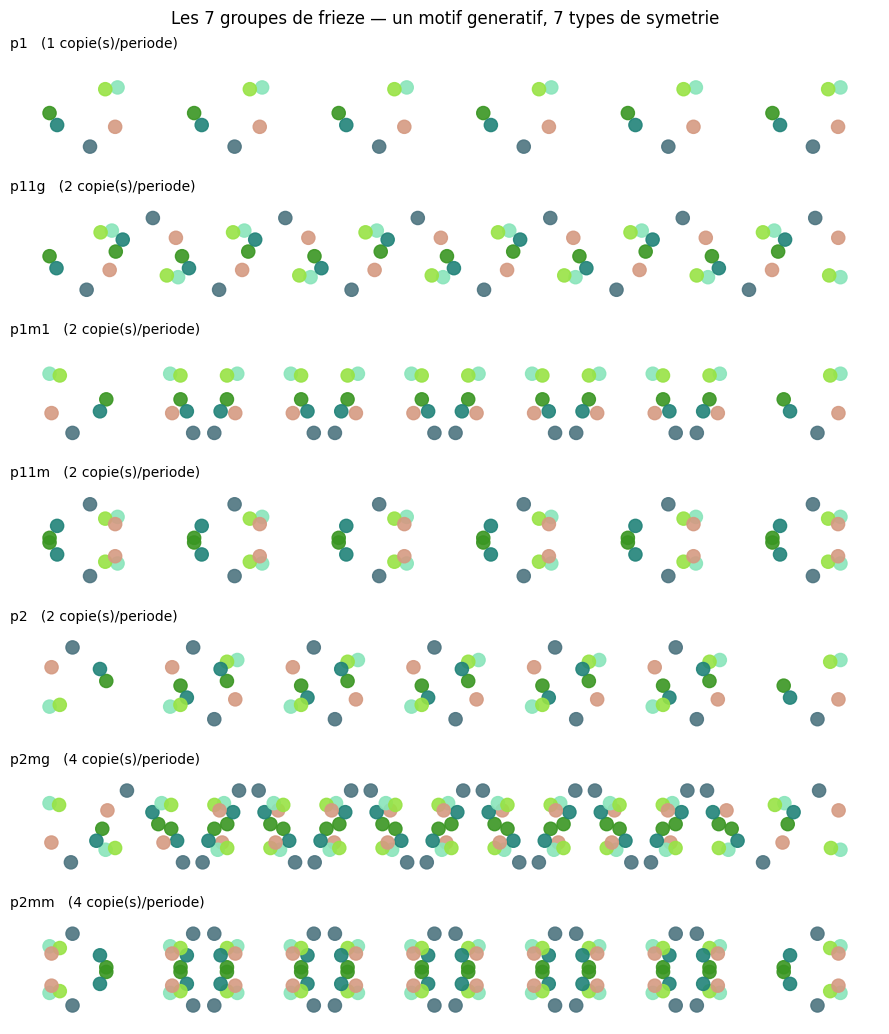

In [3]:
def render_frieze(group, motif_pts, motif_cols, L=1.0, n_periods=6):
    """Remplit la fenetre [0, n_periods*L] par l'orbite du motif sous le groupe."""
    xs, ys, cs = [], [], []
    for k in range(n_periods):
        for (px, py), col in zip(motif_pts, motif_cols):
            for sx, sy, dx in FRIZE[group]:
                xs.append(sx * px + (float(dx) + k) * L)
                ys.append(sy * py)
                cs.append(col)
    return np.array(xs), np.array(ys), np.array(cs)


groups = list(FRIZE)
fig, axes = plt.subplots(len(groups), 1, figsize=(9, 1.5 * len(groups)))
for ax, g in zip(axes, groups):
    pts, cols = make_motif(SEED)                    # meme motif de base pour les 7 bandes
    xs, ys, cs = render_frieze(g, pts, cols)
    ax.scatter(xs, ys, c=cs, s=90, alpha=0.9)
    ax.set_title(f"{g}   ({N_COPIES[g]} copie(s)/periode)", loc="left", fontsize=10)
    ax.set_ylim(-0.75, 0.75)
    ax.set_yticks([]); ax.set_xticks([])
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Les 7 groupes de frieze — un motif generatif, 7 types de symetrie")
fig.tight_layout()
plt.show()


### Lecture du résultat

Les 7 bandes partagent le **même motif de base** (tiré au hasard, seed `SEED`) ; seul l'**ensemble des opérations** change. On voit directement :

- `p1` : le motif se répète à l'identique ;
- `p11g` : un jumeau **retourné** apparaît, décalé d'un **demi-période** (c'est le glissement — le trait le plus subtil à repérer) ;
- `p1m1` / `p11m` / `p2` : un jumeau en **miroir vertical** / **miroir horizontal** / **à l'envers** ;
- les deux groupes à 4 copies (`p2mg`, `p2mm`) : la cellule fondamentale est plus riche, d'où une densité de points double.

C'est tout l'intérêt de l'art génératif : la **structure** (le groupe) est fixe et classifiable, l'**instance** (le motif) est nouvelle à chaque tirage. Re-exécuter la cellule de rendu (avec un autre `SEED`) donne 7 bandes *différentes* mais *du même type*.

In [4]:
def cloture(operations) -> frozenset[Operation]:
    """Fermer des operations par composition, modulo la translation entiere."""
    ferme = {normaliser(op) for op in operations}
    while True:
        produits = {composer(a, b) for a in ferme for b in ferme}
        if produits <= ferme:
            return frozenset(ferme)
        ferme |= produits


def translater_origine(operations, c) -> frozenset[Operation]:
    """Exprimer les operations en coordonnees X = x - c."""
    c = Fraction(str(c))
    return frozenset(
        normaliser((sx, sy, dx + (sx - 1) * c))
        for sx, sy, dx in operations
    )


def signature_ensemble(operations) -> tuple[int, bool, bool, bool]:
    """Calculer (copies, glissement, miroir_v, miroir_h) sur l'ensemble ferme."""
    ferme = cloture(operations)
    return (
        len(ferme),
        any(sx == 1 and sy == -1 and dx != 0 for sx, sy, dx in ferme),
        any(sx == -1 and sy == 1 for sx, sy, dx in ferme),
        any(sx == 1 and sy == -1 and dx == 0 for sx, sy, dx in ferme),
    )


FERMETURES = {groupe: cloture(ops) for groupe, ops in FRIZE.items()}


def signature(groupe: str) -> tuple[int, bool, bool, bool]:
    """Deduire la signature du groupe ferme, sans liste d'operations manuscrite."""
    return signature_ensemble(FERMETURES[groupe])


for groupe, ferme in FERMETURES.items():
    assert ferme == frozenset(FRIZE[groupe])
    print(f"{groupe:6s}  ferme: {len(ferme)} operations  signature: {signature(groupe)}")
print(f"\nLes 7 signatures sont distinctes : {len({signature(g) for g in FRIZE}) == 7}")

# Controle positif historique : table de l'ancien carnet au commit d94eef4645.
ANCIEN_P2GG = (
    (1, 1, 0),                 # identite
    (1, -1, Fraction(1, 2)),  # glissement
    (-1, -1, 0),               # rotation
    (-1, 1, Fraction(1, 2)),  # miroir vertical decale
)
ancien_ferme = cloture(ANCIEN_P2GG)
assert signature_ensemble(ancien_ferme) == signature("p2mg")
assert translater_origine(ancien_ferme, Fraction(1, 4)) == FERMETURES["p2mg"]
print("\nControle positif : ancien p2gg ferme -> p2mg")
print("Signature :", signature_ensemble(ancien_ferme))
print("Egalite exacte apres translation d'origine c = 1/4 : True")


p1      ferme: 1 operations  signature: (1, False, False, False)
p11g    ferme: 2 operations  signature: (2, True, False, False)
p1m1    ferme: 2 operations  signature: (2, False, True, False)
p11m    ferme: 2 operations  signature: (2, False, False, True)
p2      ferme: 2 operations  signature: (2, False, False, False)
p2mg    ferme: 4 operations  signature: (4, True, True, False)
p2mm    ferme: 4 operations  signature: (4, False, True, True)

Les 7 signatures sont distinctes : True

Controle positif : ancien p2gg ferme -> p2mg
Signature : (4, True, True, False)
Egalite exacte apres translation d'origine c = 1/4 : True


## Exercice 1 — Reconnaître un groupe à sa signature

Une bande peut être caractérisée par sa **signature** à 4 composantes : le nombre de **copies** par période, la présence d'un **glissement**, la présence d'un **miroir vertical**, et la présence d'un **miroir horizontal**. Les 7 signatures sont distinctes :

| Groupe | (copies, glissement, miroir_v, miroir_h) |
|--------|:----------------------------:|
| `p1`   | (1, F, F, F) |
| `p11g` | (2, V, F, F) |
| `p1m1` | (2, F, V, F) |
| `p11m` | (2, F, F, V) |
| `p2`   | (2, F, F, F) |
| `p2mg` | (4, V, V, F) |
| `p2mm` | (4, F, V, V) |

Complétez `identify(n_copies, a_glide, a_mirror_v, a_mirror_h)` pour qu'elle renvoie le nom du groupe.

In [5]:
def identify(n_copies: int, a_glide: bool, a_mirror_v: bool, a_mirror_h: bool) -> str:
    """Renvoie le nom du groupe de frieze a partir de sa signature (4 composantes).

    Parametres
    ----------
    n_copies   : nombre de copies du motif dans la cellule fondamentale
    a_glide    : la bande contient-elle un glissement-reflexion ?
    a_mirror_v : la bande contient-elle un miroir vertical ?
    a_mirror_h : la bande contient-elle un miroir horizontal ?

    Retour
    ------
    str : le nom du groupe parmi les cles de FRIZE
    """
    # TODO etudiant : completer a partir du tableau des signatures ci-dessus
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois la fonction completee) :
# assert identify(1, False, False, False) == "p1"
# assert identify(2, True,  False, False) == "p11g"
# assert identify(2, False, True,  False) == "p1m1"
# assert identify(2, False, False, True ) == "p11m"
# assert identify(2, False, False, False) == "p2"
print("Exercice 1 a completer : identify()")

Exercice 1 a completer : identify()


## Exercice 2 — Enrichir un groupe d'une symétrie

Pour explorer *quand* deux groupes sont proches, on peut ajouter une opération à un groupe existant. Complétez `add_symmetry(group, new_op)` : elle renvoie la liste des opérations de `group` **enrichie** de `new_op`, sans la dupliquer si elle y figure déjà.

> `new_op` est maintenant un triplet affine `(sx, sy, dx)`, comme dans `symmetry_art.FRIEZE_OPERATIONS`. Par exemple, `(-1, 1, 0)` est un miroir vertical. La normalisation ramène `dx` modulo une période ; cette simple addition ne garantit pas encore la fermeture par composition, que `cloture()` permet justement d'obtenir.


In [6]:
def add_symmetry(group: str, new_op) -> list[Operation]:
    """Renvoie les operations de `group` enrichies de `new_op`, sans doublon.

    Parametres
    ----------
    group  : une cle de FRIZE, ex. "p11m"
    new_op : un triplet affine (sx, sy, dx), dx etant ramene modulo 1
    """
    # TODO etudiant : partir de FRIZE[group], normaliser new_op, puis l'ajouter s'il y manque
    result = None  # TODO etudiant
    return result


# Auto-test (doit passer une fois completee) :
# assert len(add_symmetry("p1", (-1, 1, 0))) == 2
# assert add_symmetry("p11m", (1, -1, 0)) == list(FRIZE["p11m"])
print("Exercice 2 a completer : add_symmetry()")


Exercice 2 a completer : add_symmetry()


## Exercice 3 — Compter les motifs d'une bande

Combien de **points** (toutes copies confondues) la fonction `render_frieze` place-t-elle pour un groupe donné sur `n_periods` périodes, si le motif de base compte `n_pts` points ?

> Indice : c'est un simple produit — `n_pts` × (copies du groupe) × `n_periods`.

In [7]:
def count_motifs(group: str, n_periods: int, n_pts: int = 6) -> int:
    """Nombre total de points places par render_frieze sur n_periods periodes."""
    # TODO etudiant : n_pts * (copies du groupe) * n_periods
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois completee) :
# assert count_motifs("p1", 6)   == 6 * 1 * 6
# assert count_motifs("p2mm", 6) == 6 * 4 * 6
print("Exercice 3 a completer : count_motifs()")

Exercice 3 a completer : count_motifs()


### Pour aller plus loin

Les friezes sont le cas **1D** de la classification des groupes de symétrie du plan. Les deux généralisations naturelles se trouvent déjà dans le dépôt :

- **les 17 groupes de pavage (wallpaper)** : symétries 2D d'un motif qui pave tout le plan (murs, papiers peints, cristaux 2D). La section 6 de [05-0](05-0-Generateurs-Symboliques.ipynb) les engendre et en déduit les invariants (réseau de Bravais, groupe ponctuel, miroirs, glissements) en arithmétique rationnelle exacte, avec le moteur [`scripts/symmetry/`](../../../../scripts/symmetry/README.md) ; le groupe `p4m` est formalisé en Lean dans [WallpaperP4m.lean](../../../SymbolicAI/Lean/mathlib_examples/MathLibExamples/WallpaperP4m.lean) ;
- **les groupes de rosettes** : symétries d'un motif à centre, sans translation (roses, mandalas) — cycliques `C_n` et diédraux `D_n`, construits par la fonction `rosette` du module [`symmetry_art.py`](symmetry_art.py) de ce rayon, qui porte aussi les 7 groupes de frise sous forme de table d'opérations.

Le même mécanisme — *motif de base + opérations du groupe = orbite* — s'y applique, avec plus d'opérations à combiner (c'est pourquoi il y en a 17 en 2D, contre 7 en 1D).

**Rayon** : [05-History — index](README.md) · [05-0](05-0-Generateurs-Symboliques.ipynb) (générateurs symboliques) → *frieze* (ce carnet).